In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import seaborn as sns

In [15]:
INPUT_FILE = 'IO\\fluorescence_spectroscopy\\lettuce_fluor.csv'

data = pd.read_csv(INPUT_FILE, skiprows=1, header=None).iloc[:, 1:].T
data = data.set_index("Time(s)") if "Time(s)" in data.columns else data.set_index(data.columns[0])
data.index.name = "Time(s)"

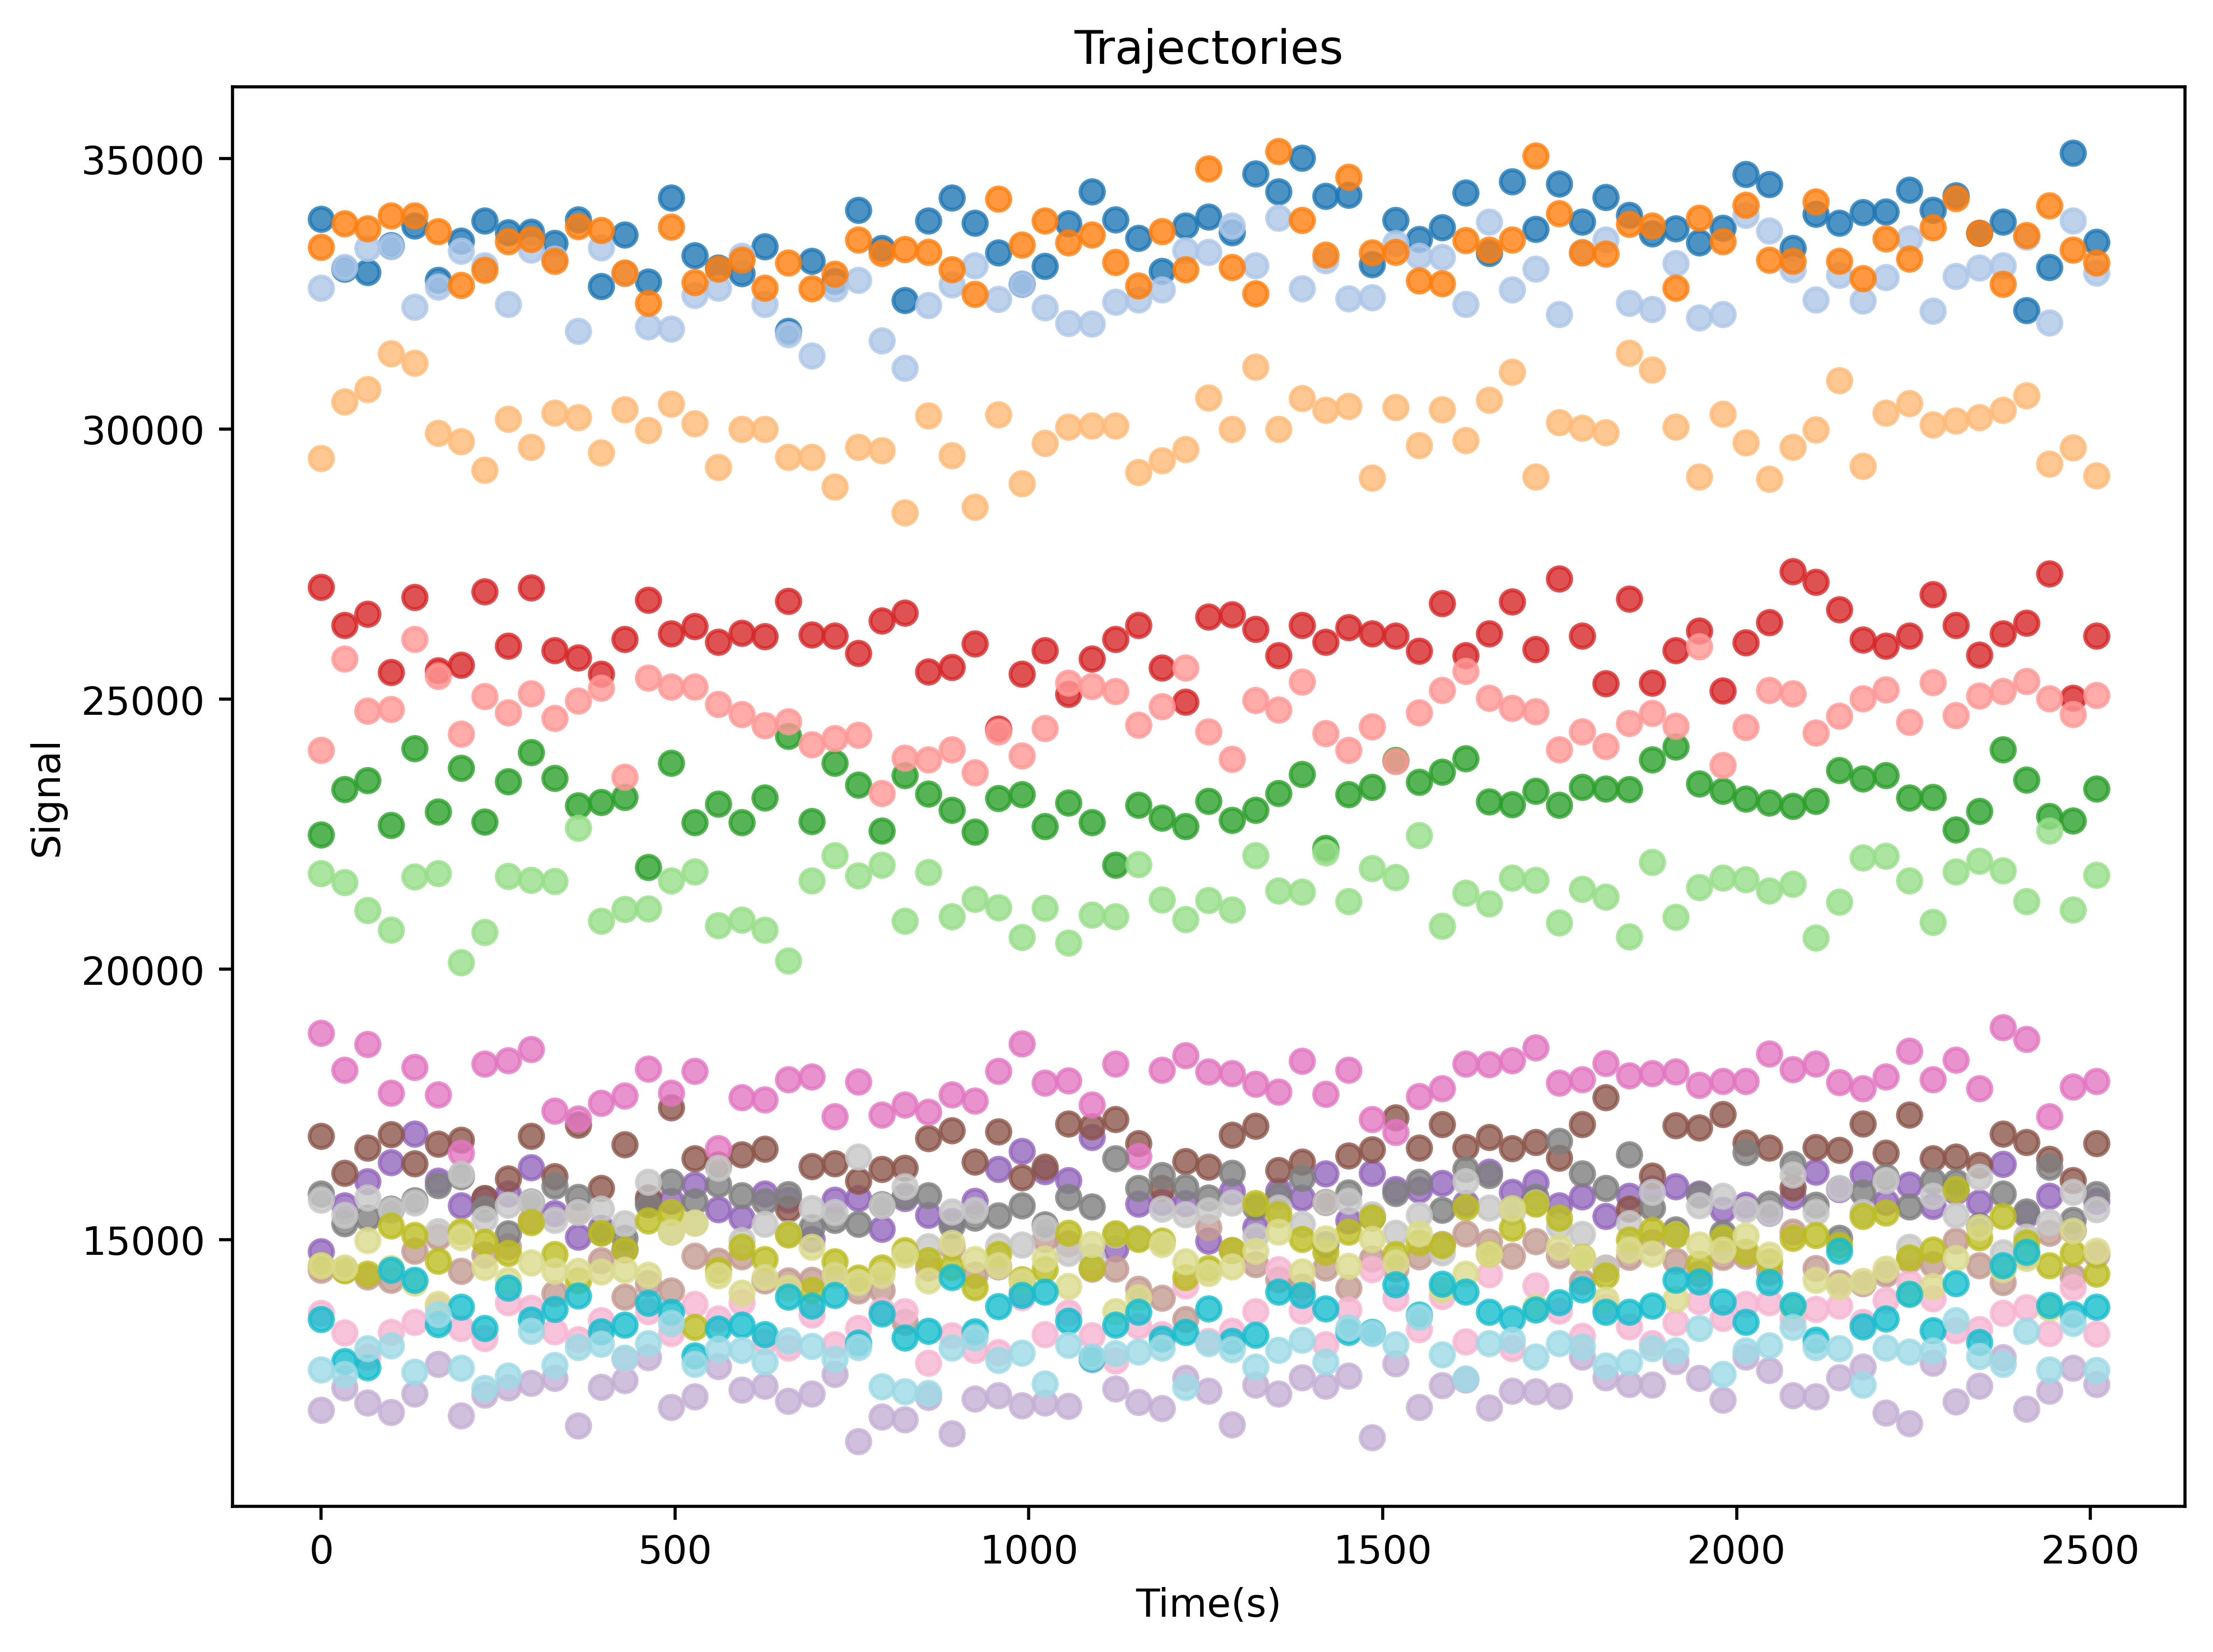

In [20]:
fig, ax = plt.subplots(figsize=(8,6), dpi=500)

time = pd.to_numeric(data.index, errors="coerce")
df_num = data.apply(pd.to_numeric, errors="coerce")
valid = time.notna()
time = time[valid]
df_num = df_num.loc[valid]

cmap = sns.color_palette("tab20", n_colors=len(df_num.columns))

for col in df_num.columns:
    ax.scatter(time, df_num[col], alpha=0.8, label=str(col), color=cmap[df_num.columns.get_loc(col)])

ax.set_xlabel("Time(s)")
ax.set_ylabel("Signal")
ax.set_title("Trajectories")
#ax.legend(fontsize=7, ncol=2, frameon=True)
plt.tight_layout()
plt.show()